In [1]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import json

from pathlib import Path
from skimage.metrics import structural_similarity

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("SSIM library imported successfully.")

SSIM library imported successfully.


In [3]:
def calculate_ssim(reference, estimate):
    reference = np.asarray(reference, dtype=np.float64)
    estimate = np.asarray(estimate, dtype=np.float64)

    if reference.shape != estimate.shape:
        raise ValueError(
            "Reference and estimate must have the same shape."
        )

    data_range = float(
        np.max(reference) - np.min(reference)
    )

    if data_range <= 0:
        raise ValueError(
            "Reference image must have a non-zero intensity range."
        )

    return float(
        structural_similarity(
            reference,
            estimate,
            data_range=data_range
        )
    )

In [5]:
def calculate_ssim(reference, estimate):
    reference = np.asarray(reference, dtype=np.float64)
    estimate = np.asarray(estimate, dtype=np.float64)

    if reference.shape != estimate.shape:
        raise ValueError(
            "Reference and estimate must have the same shape."
        )

    data_range = float(
        np.max(reference) - np.min(reference)
    )

    if data_range <= 0:
        raise ValueError(
            "Reference image must have a non-zero intensity range."
        )

    # Choose an odd window size that fits the image
    min_dim = min(reference.shape)

    win_size = min(7, min_dim if min_dim % 2 == 1 else min_dim - 1)

    if win_size < 3:
        raise ValueError(
            "Images must be at least 3x3 for this SSIM implementation."
        )

    return float(
        structural_similarity(
            reference,
            estimate,
            data_range=data_range,
            win_size=win_size
        )
    )

In [6]:
test_image = np.array([
    [0.0, 0.2, 0.4],
    [0.3, 0.6, 0.8],
    [0.5, 0.7, 1.0]
])

identical_ssim = calculate_ssim(test_image, test_image)

print("SSIM of identical images:", identical_ssim)

assert np.isclose(identical_ssim, 1.0)
print("SSIM validation passed.")

SSIM of identical images: 1.0
SSIM validation passed.


In [9]:
import numpy as np

# Simulation parameters
num_sensors = 32
num_samples = 600

fs = 10e6
dt = 1 / fs
c = 1500.0

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)
time = np.arange(num_samples) * dt

# Generate synthetic sensor signals
signals = np.zeros((num_sensors, num_samples))

for i in range(num_sensors):
    distance = np.sqrt(
        (source_x - sensor_x[i])**2 + source_y**2
    )
    arrival_time = distance / c

    signals[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

# Image grid
x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

# DAS reconstruction function
def reconstruct_das(signal_matrix):
    image = np.zeros_like(X, dtype=float)

    for i in range(num_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i])**2 + Y**2
        )

        travel_time = distance_map / c
        indices = np.rint(travel_time / dt).astype(int)

        valid = (indices >= 0) & (indices < num_samples)
        sampled = np.zeros_like(X, dtype=float)
        sampled[valid] = signal_matrix[i, indices[valid]]

        image += sampled

    return image

# Full-array reference image
reference_image = reconstruct_das(signals)

print("Reference image created:", reference_image.shape)

Reference image created: (100, 100)


In [10]:
from scipy.interpolate import interp1d, CubicSpline

# Use the same 8 inactive sensors for all methods
inactive_indices = np.array(
    [2, 12, 17, 20, 22, 25, 28, 30]
)

active_indices = np.setdiff1d(
    np.arange(num_sensors),
    inactive_indices
)

# Simulate inactive sensors
damaged_signals = signals.copy()
damaged_signals[inactive_indices, :] = 0.0

# Incomplete reconstruction
incomplete_image = reconstruct_das(damaged_signals)

# Linear interpolation
linear_signals = damaged_signals.copy()

linear_interp = interp1d(
    sensor_x[active_indices],
    signals[active_indices, :],
    axis=0,
    kind="linear",
    bounds_error=False,
    fill_value="extrapolate"
)

linear_signals[inactive_indices, :] = linear_interp(
    sensor_x[inactive_indices]
)

linear_image = reconstruct_das(linear_signals)

# Cubic spline interpolation
spline_signals = damaged_signals.copy()

spline_interp = CubicSpline(
    sensor_x[active_indices],
    signals[active_indices, :],
    axis=0,
    extrapolate=True
)

spline_signals[inactive_indices, :] = spline_interp(
    sensor_x[inactive_indices]
)

spline_image = reconstruct_das(spline_signals)

print("Reference:", reference_image.shape)
print("Incomplete:", incomplete_image.shape)
print("Linear:", linear_image.shape)
print("Spline:", spline_image.shape)

Reference: (100, 100)
Incomplete: (100, 100)
Linear: (100, 100)
Spline: (100, 100)


In [11]:
images = {
    "Reference": reference_image,
    "Incomplete": incomplete_image,
    "Linear": linear_image,
    "Spline": spline_image
}

for name, image in images.items():
    print(name, np.asarray(image).shape)

Reference (100, 100)
Incomplete (100, 100)
Linear (100, 100)
Spline (100, 100)


In [12]:
ssim_results = {
    "reference": "Full-array DAS image",
    "inactive_sensor_count": 8,
    "inactive_sensor_percentage": 25.0,
    "ssim": {}
}

for method in ["Incomplete", "Linear", "Spline"]:
    score = calculate_ssim(
        reference_image,
        images[method]
    )

    ssim_results["ssim"][method] = score
    print(f"{method} SSIM: {score:.6f}")

Incomplete SSIM: 0.931107
Linear SSIM: 0.999949
Spline SSIM: 1.000000


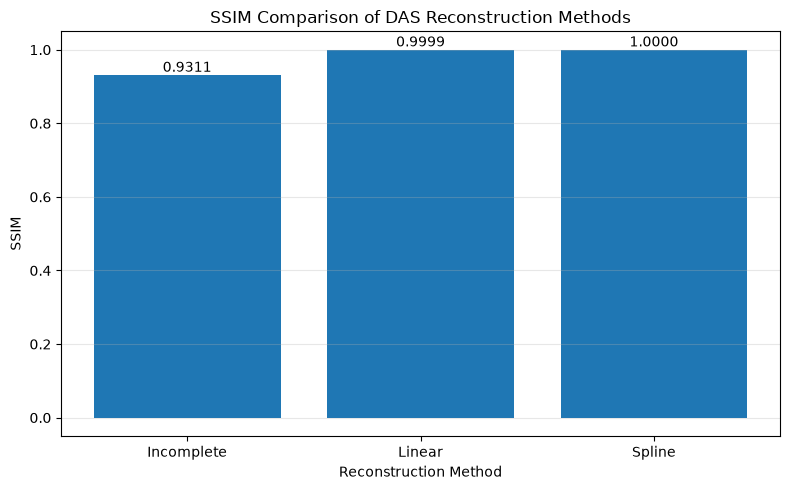

In [13]:
import matplotlib.pyplot as plt

methods = list(ssim_results["ssim"].keys())
scores = [
    ssim_results["ssim"][method]
    for method in methods
]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, scores)

plt.ylim(min(-0.05, min(scores) - 0.05), 1.05)
plt.ylabel("SSIM")
plt.xlabel("Reconstruction Method")
plt.title("SSIM Comparison of DAS Reconstruction Methods")
plt.grid(axis="y", alpha=0.3)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{score:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "../outputs/day47_ssim_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
import json
from pathlib import Path

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(
    OUTPUT_DIR / "day47_ssim_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        ssim_results,
        f,
        indent=4,
        ensure_ascii=False
    )

print("JSON saved:", OUTPUT_DIR / "day47_ssim_results.json")
print("Plot saved: ../outputs/day47_ssim_comparison.png")

JSON saved: ..\outputs\day47_ssim_results.json
Plot saved: ../outputs/day47_ssim_comparison.png
